`devices/block.ch`
   Provides sector-based read and write access to block devices.

`devices/swap.ch`
   Provides page-based read and write access to the swap partition. You
   will use this interface to access the swap partition, as wrapper around
   a block device.

```c
void swap_init (void);
size_t swap_out (const void *vaddr)
void swap_in (void *vaddr, size_t slot);
void swap_drop (size_t slot);
```

`swap_init`
   It finds the swap disk with `block_get_role (BLOCK_SWAP)` and creates a 
   bitmap with one bit per page-sized slot on that disk. If there is no swap
   disk it prints a message and creates an empty bitmap, so every later
   `swap_out` fails. `threads/init.c` line 136 calls it once at boot, and 
   it also sets up `swap_lock`.


`swap_out (const void *vaddr)`
   It finds a free slot in the bitmap and marks it as used while it holds 
   `swap_lock`. Then it writes the page at `vaddr` to the slot's 8 sectors
   with `block_write` and returns the slot number. If swap is full it 
   returns `BITMAP_ERROR` and writes nothing. 



-- A frame is a 4 KB slot of physical memory
   A page is a 4 KB slot of process' virtual memory
   So one frame holds exactly one page, and a page table entry is the link 
   that maps that page to its frame. ... 

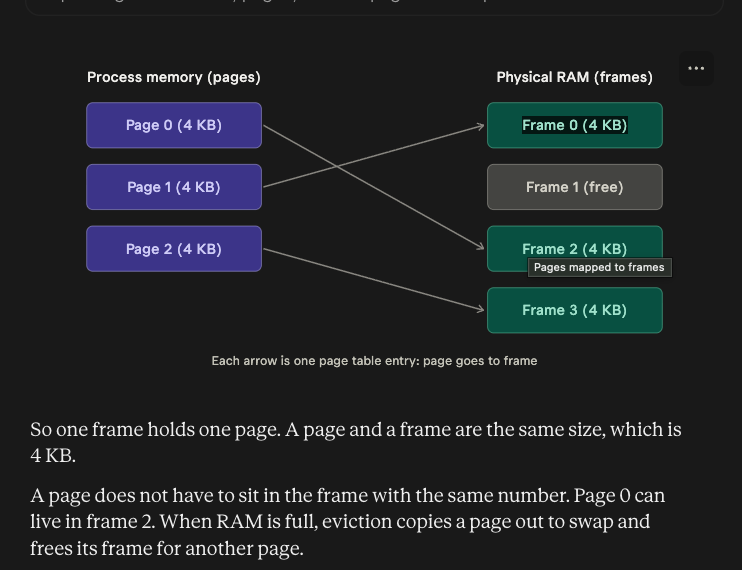

   The array is the page table, and a PTE is one 32-bit slot in 
   that array. The CPU picks which slot to read using bits of the
   virtual address, so the slot never needs to store the virtual
   address itself. What the slot does store is the physical adddress of the
   frame in its top 20 bits, plus flag bits such as present, writable, 
   accessed, and ddirty. So 

---

```c
/* Page directory and page table entries.

   For more information see the section on page tables in the
   PintOS reference guide chapter, or [IA32-v3a] 3.7.6
   "Page-Directory and Page-Table Entries".

   PDEs and PTEs share a common format:

   31                                 12 11                     0
   +------------------------------------+------------------------+
   |         Physical Address           |         Flags          |
   +------------------------------------+------------------------+

   In a PDE, the physical address points to a page table.
   In a PTE, the physical address points to a data or code page.
   The important flags are listed below.
   When a PDE or PTE is not "present", the other flags are
   ignored.
   A PDE or PTE that is initialized to 0 will be interpreted as
   "not present", which is just fine. */
#define PTE_FLAGS 0x00000fff    /* Flag bits. */
#define PTE_ADDR  0xfffff000    /* Address bits. */
#define PTE_AVL   0x00000e00    /* Bits available for OS use. */
#define PTE_P 0x1               /* 1=present, 0=not present. */
#define PTE_W 0x2               /* 1=read/write, 0=read-only. */
#define PTE_U 0x4               /* 1=user/kernel, 0=kernel only. */
#define PTE_A 0x20              /* 1=accessed, 0=not acccessed. */
#define PTE_D 0x40              /* 1=dirty, 0=not dirty (PTEs only). */

```

   The array is the page table, and a PTE is one 32-bit slot in that
   array. The CPU picks which slot to read using bits of the virtual address.
   The slot stores the physical address of the frame (in physical memory)
   in its top 20 bits, (bottom 20 bits) store the flag bits such as 
   `present`, `writable`, `accessed`, and `dirty`. So the PTE's job is 
   "this page lives in that frame", and in PintOS `pagedir_set_page`
   is the function that fills one in? 

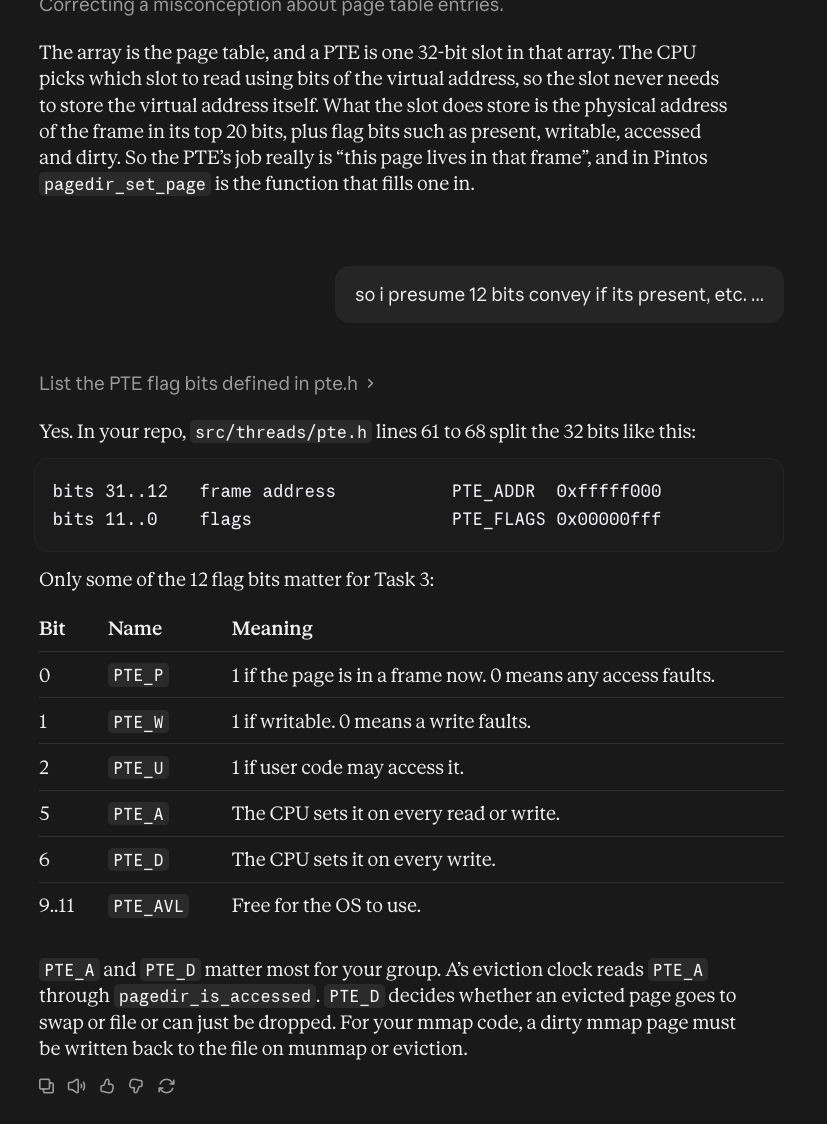

---

-- a frame, ... `FRAME` == `physical frame` or `page frame`, is a continuous
   region of physical memory. Like pages, frames must be page-sized and 
   page-aligned. 

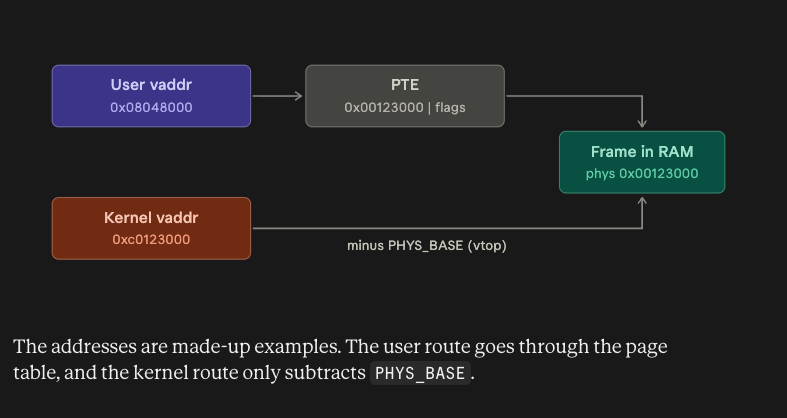

   PD, PT, PTEs ... where do they live?

-- They live only in the kernel pool of physical memory, so the kernel reaches
   them through kernel virtual addresses and user code never touches them. 

   ... `pagedir_create` ... gets the page directory with `palloc_get_page (0)`,
   and `lookup_page` gets each page table the same way without `PAL_USER`. 
   In your picture, that puts them in the "Kernel pool" ban on the right and in 
   "Kernel view of the kernel pool" on the left

   Yes, the kernel finds them easily because `struct process` stores the 
   kernel address in `pagedir`, which is why your code writes 
   `thread_current ()->process->pagedir`. The CPU itself uses a different route:
   `pagedir_activate` at line 257 loads the physical address `vtop (pd)`
   into the CR3 register on each context switch ... 



---

   You will need to design the following data structures:

   - SUPPLEMENTAL PAGE TABLE
      Enables page fault handling by supplemnting the page table ... 
   - FRAME TABLE
      Allows efficient implementaiton of eviction policy... 
   - TABLE OF FILE MAPPINGS
      Process may map files into their virtual memory space. You need a table
      to track which files are mapped into which pages ... 

---
   In Pintos, the `FRAME TABLE` is a kernel data structure that tracks physical
   memory frames allocated to user pages so the OS can manage 

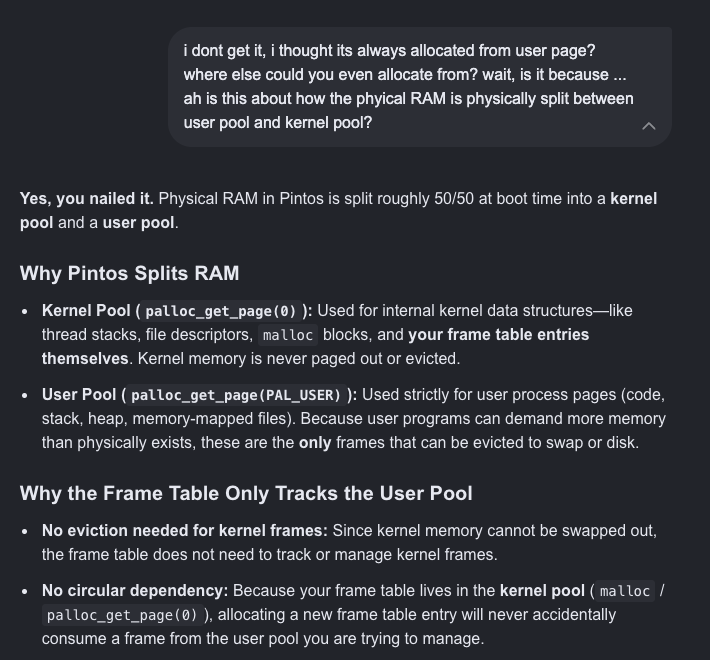

# Purposes of Supplemental Page Table
-- On a page fault, the kernel looks up the virtual page that faulted in
   the supplemental page table table to find out what data should be
   there. 
        -- `page_fault ()` of `userprog/exception.c`
            <-- `MOST IMPORTANT USER !!!`
-- Second, the kernel consults the supplemental page table when a process
   terminates, to decide what resources to free. 


---

-- An entry is not present when the page has no frame right now, and in Task 3
   that is often on purpose. With lazy loading a code, data, or mmap page gets
   no frame until its first access, and an evicted page loses its frame
   when it goes to swap or back to its file ..

   A PDE can also be not present beccause no page table exists yet for that 4 MB
   region, as `lookup_page` only creates one page when a page there is first
   mapped. A permission fault happens when the pTE exists but forbids the
   access, such as a write to a  read-only code page ... 



---

   Your page fault handler, ... implement by modifying `page_fault ()` in
   `userprog/exception.c`, needs to do the following

In [ ]:
-- ... a page ƒault happens whenever a running thread accesses a virtual 
   address whose PDE or PTE is marked not present in physical memory ... 

-- In PintOS, a `bitmap` is a fixed-size array of boolean bits (1 or 0)
   implemented in ... used to track the allocation or usage status of 
   identical resources.

   Internally, a `struct bitmap` stores the total number of bits (`bit_cnt`)
   alongside an array of integer elements (`bits`) that group bits together ... 

-- a page in PintOS is 4096 bytes (4 KB), whereas a block sector is 512 bytes
   
   Because this size difference, one memory page equals 8 disk sectors ...

   


-- block = disk or partition
-- block sector = 512 bytes sector


-- ... a `struct block` can be a whole disk (registered as `BLOCK_RAW`)
   or a signle partition ... Sector number always count from the start of that
   block, so sector 0 of a partition is turned into disk sector ... 

---

   1. Locate the page that faulted in the supplemental page table. If the 
      memory reference is valid, use the supplemental page table entry to 
      locate the data that goes in the page, (which might be in the file
      system, or in a swap slot, or it might simply be an all-zero page).
      When you implement sharing, the page's data might even already be in a 
      page frame, but not in the page table. 

      If the supplemental page table indicates that the user process should not
      expect any data at the address it was trying to access, or if the page 
      lies within virtual memory... or if the .. any invalid access terminates 
      the process and thereby frees all of its resources.

   2. Obtain a frame to store the page. See... 

   3. Fetch the data into the frame, by reading it from the file system or swap,
      zeroing it, etc. 

      When you implement sharing, the page you need may already be in the frame,
      in which case no action is necessary??? wtf is sharing... 

---

-- Sharing means two processes use one frame for the same page instead of 
   loading two copies. It works for read-only code pages, because two processes
   running the same program (two `echo` process, say) have identical code 
   that neither can change ... so when process 2 fauls on a code page that
   process 1 already loaded, the data is arleady in a frame and process 2's PTE
   just points at that frame without any file read ... 

---
   ... the fault happens because process 2's own PTE for that page is not 
   present yet. Each process has its own page table, so the CPU never knows
   that process 1 already loaded that code into a frame. The fault handler finds
   the existing frame in A's share table and fills in process 2's PTE, so it
   skips the file read. 

   ... sharing is not the first purpose of the supplemental PT

   The first purpose is telling the fault handler where a page's data is...
   Sharing uses a separate structure, ... a `SHARE TABLE`. It is the one 
   global table for all processes, while each process has its own supplemental
   page table. 

   The two work one after the other on a fault ... The supplemental table says
   "file X at offset Y", and only then does the share table check whether
   a frame already holds that file page .. 

---

   FILE MAPPINGS track how files are mapped into a process's
   virtual address space--typically via the `mmap` and `munmap` system calls.

   Rather than using `read` or `write` system calls, a process accesses file
   contents directly through memory pointers in its virtual address space,
   with pages faulted in lazily on demand ... 

---

# 5.3.4 Memory Mapped Files
   Implement memory mapped files, including following system calls... 


`mapid_t mmap (int fd, void *addr) {}`
   Maps the file open as `fd` into the process's VADDR. The entire file is
   mapped into consecutive virtual pages starting at `ADDR`.

   Your VM system must lazily load pages in `mmap` regions and use the 
   `mmap`ed file itself as backing store for the mapping. That is, evicting a 
   page mapped by `mmap` writes it back to the file it was mapped from ... 

   If the file length is not a multiple of `PGSIZE`, then some bytes in the 
   final mapped page "stick out" beyond the end of the file. Set these bytes
   to zero when the page is fauled in from the file system, and discard them
   when the page is written back to disk.

   If successful, this function returns a MAPPING ID, that uniquely identiies
   the mapping within the process. On failure ... otherswise should not be a
   valid mapping `id`

   ... A call to `mmap` may fial if the file open as a fd has ... it must 
   fail if ... or if ... the range of pages mapped overlaps any existing set of
   mapped pages, including the space ... It must also fail if addr is 0 ... 
   becuase some PintOS code assumes virtual page 0 is not mapped. Finally ...
   FD 0 and 1 representing console input and output are not mappable ... 

---

`void munmap (mapid_t mapping)`
   Unmaps the mapping designated by `MAPPING`... which must be a `mapid_t`
   returned by a previous call to `mmap` by the same process that has not yet
   been unmapped ...

---

   All mappings are implicitly unmapped when a process exits, whether via
   `exit` or by any other means... When a mapping is unmapped, whether 
   implicitly or explicitly, all pages written to by the process are written
   back to the file ... and pages not written must not be... 

   SPT == Supplemental Page Table

-- "Memory Mapped Files": It explains the failure rules, the zeroed tail, 
   using `file_reoopen` for each mapping, and that only written pages go back.

# FREEDOM
   You will have the freedom to choose:
   - how to handle page faults
   - how to organise the swap partition
   - how to implement paging 